# Step 2: Competitive Landscape

## 2.1 Basic Imports and Data Loading

In [3]:
import re
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats                      # linear regression (Lotka) and Kendall's tau
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # applications
    TLS202_APPLN_TITLE,         # titles
    TLS203_APPLN_ABSTR,         # abstracts
    TLS206_PERSON,              # persons: standardised name, sector, country
    TLS207_PERS_APPLN,          # person <-> application links (applicant / inventor)
    TLS209_APPLN_IPC,           # IPC classification
    TLS211_PAT_PUBLN,           # publications: grants and their dates
    TLS224_APPLN_CPC,           # CPC classification
)

In [4]:
# read HuggingFace token:

with open("hf_token.txt", "r", encoding="utf-8") as f:
    hf_token = f.read().strip()

In [5]:
# ---------------------------------------------------------------- environment
ENV = "TEST"                         # develop on TEST, switch to "PROD" for the final numbers

# ---------------------------------------------------------------- applicant names (Section 2)
NAME_METHOD = "dictionary"           # "psn" (PATSTAT names as they are), "dictionary" or "cleanco"
GOLD_STANDARD_FILE = "PATSTAT_500_label_datav4.csv"   # hand-labelled names (Section 2.4), in the same folder as this notebook

# ---------------------------------------------------------------- replication (Section 4): the paper's design
REPL_OFFICE = "US"                                      # USPTO patents...
REPL_GRANTED = (date(1976, 1, 1), date(2002, 12, 31))   # ...granted between these two dates
REPL_KEYWORDS = ("fuel cell",)                          # searched in titles and abstracts
REPL_CLASSES = ("H01M8",)                               # IPC/CPC H01M 8: fuel cells
REPL_SELECTION = "keywords or classes"                  # "keywords", "classes" or "keywords or classes"
PAPER_COUNTRIES = ("AU", "CA", "FR", "DE", "IL", "IT", "JP", "NL", "SE", "CH", "GB", "US")

# ---------------------------------------------------------------- your sector (Section 5): replace with your Step 1
SECTOR_NAME = "Surface Drones"

SECTOR_CPC_PREFIXES = (
    # Primary classification codes for Unmanned Surface Vessels (USVs)
    "B63B2035/006",  # Unmanned surface vessels, e.g. remotely controlled
    "B63B2035/007",  # Unmanned surface vessels, autonomously operating
    "B63B2035/008",  # Unmanned surface vessels, remotely controlled

    # Vessel Control, Navigation, and Autonomy
    "G05D1/00",      # Control of position, course, altitude or attitude of land, water, air, or space vehicles (Autopilot/Autonomous navigation)
    "G05D1/0206",    # Control of position or course of waterborne vessels
    "G08G3/00",      # Traffic control systems for marine craft

    # Waterborne craft adapted for special or military purposes
    "B63B35/00",     # Vessels or floating structures specially adapted for specific purposes
    "B63G8/001",     # Unmanned underwater or surface-supported craft systems / deployment
    "B63G13/00",     # Defense or military features adapted for waterborne vessels

    # Hybrid & amphibious drone operations (Air-Sea interactions)
    "B64U60/10",     # UAVs specially adapted for use on water (water-landing/amphibious drones)
    "B64U70/93"      # Launching/landing UAV platforms for use on nautical vehicles
)

SECTOR_CPC_PREFIXES = (
    # Primary classification codes for Unmanned Surface Vessels (USVs)
    "B63B2035/006",  # Unmanned surface vessels, e.g. remotely controlled
    "B63B2035/007",  # Unmanned surface vessels, autonomously operating
    "B63B2035/008",  # Unmanned surface vessels, remotely controlled

    # Vessel Control, Navigation, and Autonomy
    "G05D1/00",      # Control of position, course, altitude or attitude of land, water, air, or space vehicles (Autopilot/Autonomous navigation)
    "G05D1/0206",    # Control of position or course of waterborne vessels
    "G08G3/00",      # Traffic control systems for marine craft

    # Waterborne craft adapted for special or military purposes
    "B63B35/00",     # Vessels or floating structures specially adapted for specific purposes
    "B63G8/001",     # Unmanned underwater or surface-supported craft systems / deployment
    "B63G13/00",     # Defense or military features adapted for waterborne vessels

    # Hybrid & amphibious drone operations (Air-Sea interactions)
    "B64U60/10",     # UAVs specially adapted for use on water (water-landing/amphibious drones)
    "B64U70/93"      # Launching/landing UAV platforms for use on nautical vehicles
)

# 1. Primary Vehicle Terminology
keywords_primary = [
    "unmanned surface vehicle",
    "USV",
    "unmanned surface vessel",
    "autonomous surface vehicle",
    "ASV",
    "autonomous surface vessel",
    "unmanned surface drone",
    "maritime drone",
    "marine drone",
    "aquatic drone",
    "waterborne drone",
    "remotely operated surface vessel",
    "crewless vessel",
    "uncrewed surface vessel",
    "robotic boat",
    "robotic vessel",
    "autonomous boat",
]

# 2. Form Factor & Design Terms
keywords_form_factor = [
    "surface craft",
    "surface vessel",
    "surface platform",
    "unmanned catamaran",
    "unmanned trimaran",
    "unmanned kayak",
    "semi-submersible surface vehicle",
    "autonomous hydrofoil",
    "wave glider",
    "saildrone",
]

# 3. Subsystem & Functional Keywords
keywords_subsystems = {
    "navigation_autonomy": [
        "obstacle avoidance",
        "path planning",
        "colregs compliance",
        "collision avoidance",
        "waypoint navigation",
        "autonomous docking",
        "dynamic positioning",
    ],
    "control_telemetry": [
        "teleoperation",
        "line-of-sight communication",
        "satellite communication",
        "SATCOM",
        "tethered control",
        "ground control station",
        "GCS",
    ],
    "propulsion_energy": [
        "hybrid propulsion",
        "electric outboard",
        "wave propulsion",
        "solar sails",
        "rigid sail",
        "waterjet propulsion",
        "thruster configuration",
    ],
    "payload_deployment": [
        "LARS",
        "launch and recovery system",
        "moon pool",
        "tether winch",
        "bathymetric sonar",
        "multibeam echosounder",
        "ROV deployment",
        "UAV landing pad",
    ],
}

SECTOR_KEYWORDS = (
    keywords_primary
    + keywords_form_factor
    + [kw for sublist in keywords_subsystems.values() for kw in sublist]
)

YEAR_MIN, YEAR_MAX = 2000, 2025
LAST_COMPLETE_YEAR = YEAR_MAX - 3    # the last 3 priority years are still incomplete in PATSTAT
IPR_TYPE = "PI"                      # patents of invention only
SPLIT_YEAR = 2015                    # incumbents file before SPLIT_YEAR, entrants from SPLIT_YEAR on
WINDOW = 3                           # years per window when following concentration over time
TOP_N = 15                           # rows in the tables of top applicants

COUNTRY_NAMES = {"AU": "Australia", "CA": "Canada", "FR": "France", "DE": "Germany", "IL": "Israel", "IT": "Italy",
                 "JP": "Japan", "NL": "Netherlands", "SE": "Sweden", "CH": "Switzerland", "GB": "UK", "US": "USA"}

In [6]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

## 2. The unit of analysis: applicants
In Step 1 we counted families and applications. 
Concentration needs one more unit: the applicant, the owner of the patent.

We must decide when two names on two patents are the same applicant.

The same company appears in PATSTAT under many spellings (SIEMENS AG, Siemens Aktiengesellschaft, SIEMENS AKTIENGESELLSCHAFT MUENCHEN…). If we count each spelling as a different firm, a large firm is split into many small ones and every concentration measure is wrong. tls206_person offers:

psn_name is a good start, but it still leaves variants (TOYOTA JIDOSHA KK and TOYOTA MOTOR CORP, with and without legal forms…), and it never merges a subsidiary with its parent.

To address the issue, we'll rely on **cleanco** package:

In [7]:
%pip install -q cleanco
from cleanco import basename


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Cleaning Function

In [8]:
# Legal-form words to remove (extend the set for the countries of your sector)
LEGAL_FORMS = {
    # Existing Western & Japanese forms
    "INC", "INCORPORATED", "CORP", "CORPORATION", "CO", "COMPANY", "LTD", "LIMITED", "LLC", "LP", "PLC",
    "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS", "SPA", "SRL", "BV", "NV", "AB", "AS", "ASA", "OY", "OYJ",
    "KK", "KABUSHIKI", "KAISHA", "LTDA", "PTY", "THE", "AKTIENGESELLSCHAFT", "GESELLSCHAFT",

    # Chinese Legal Forms (English / Pinyin / Romanized tokens)
    "YOUXIAN", "GONGSI", "GUFEN", "ZEREN", "JITUAN", "HEHUO", "QIYE", "CHANG", "ZONG", "FEN",
    "HOLDING", "HOLDINGS", "GROUP", "ENTERPRISE", "ENTERPRISES", "FACTORY", "WORKS",
    "PTE",  # Common in Singapore / Chinese-owned entities in SEA
}

''' ---------------- FAULTY FUNCTION ---------------
def clean_with_dictionary(name):
    "Upper-case, keep letters and digits only, and drop legal-form words at the start and at the end."
    words = re.sub(r"[^A-Z0-9 ]", " ", str(name).upper()).split()
    while words and words[-1] in LEGAL_FORMS:      # e.g. "TOYOTA JIDOSHA KABUSHIKI KAISHA" -> "TOYOTA JIDOSHA"
        words.pop()
    while words and words[0] in LEGAL_FORMS:       # e.g. "KABUSHIKI KAISHA TOSHIBA" -> "TOSHIBA"
        words.pop(0)
    return " ".join(words)
'''

def clean_with_dictionary(name):
    raw = str(name).strip().upper()
    words = re.sub(r"[^A-Z0-9 ]", " ", raw).split()
    while words and words[-1] in LEGAL_FORMS:
        words.pop()
    while words and words[0] in LEGAL_FORMS:
        words.pop(0)
    cleaned = " ".join(words)
    return cleaned if cleaned else raw



def clean_with_cleanco(name):
    "Remove legal forms with cleanco, then apply the same upper-case cleaning as method A."
    return clean_with_dictionary(basename(str(name)))

In [9]:
def keyword_condition(terms):
    """OR-condition: any term appears in the title or in the abstract (case-insensitive)."""
    title = func.lower(TLS202_APPLN_TITLE.appln_title)
    abstract = func.lower(TLS203_APPLN_ABSTR.appln_abstract)
    return or_(
        *(title.like(f"%{t.lower()}%") for t in terms),
        *(abstract.like(f"%{t.lower()}%") for t in terms),
    )


def symbol_prefix_condition(symbol_column, codes):
    """OR-condition: the blank-stripped classification symbol starts with one of the codes."""
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


# Base columns shown for every application
APPLN_COLUMNS = (
    TLS201_APPLN.appln_id,
    TLS201_APPLN.appln_auth,
    TLS201_APPLN.appln_nr,
    TLS201_APPLN.appln_kind,
    TLS201_APPLN.appln_filing_date,
)


def query_by_keywords(*columns):
    """Applications whose title or abstract contains a surface drone keyword."""
    
    """Note: an application might have a title but not an abstract or vice-versa"""
    
    return (
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(SECTOR_KEYWORDS))
    )


def query_by_cpc(*columns):
    """Applications with at least one CPC symbol in the CPC list."""
    return (
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES))
    )

In [10]:
appln_id = TLS201_APPLN.appln_id.label("appln_id")

sd_ids = (
    query_by_keywords(appln_id)
    .union(query_by_cpc(appln_id))
    .subquery()
)

q_sd = (
    db.query(
        *APPLN_COLUMNS,
        TLS202_APPLN_TITLE.appln_title,
        TLS206_PERSON.psn_name,
        TLS206_PERSON.psn_sector,
        TLS206_PERSON.person_ctry_code,
    )
    .select_from(TLS201_APPLN)
    .join(sd_ids, TLS201_APPLN.appln_id == sd_ids.c.appln_id)
    .join(TLS207_PERS_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .outerjoin(
        TLS202_APPLN_TITLE,
        TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id
    )
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)  # Retain applicants only (if desired)
    .distinct()
    .order_by(TLS201_APPLN.appln_filing_date)
)

df_sd = patstat.df(q_sd)

In [11]:
df_sd

,appln_id,appln_auth,appln_nr,appln_kind,appln_filing_date,appln_title,psn_name,psn_sector,person_ctry_code
0,21651327,GB,1258422,A,1922-05-04,Improvements in windmills and wind-driven elec...,JOHN HALIFAX GARTY,INDIVIDUAL,
1,21622371,GB,1178225,A,1925-05-06,Method of and arrangement for preventing the f...,HERMANN FOETTINGER,INDIVIDUAL,
2,21813502,GB,1700425,A,1926-02-22,Improvements in or relating to windmills or wi...,HENRY TURNER HOWITT,INDIVIDUAL,
3,21813502,GB,1700425,A,1926-02-22,Improvements in or relating to windmills or wi...,ANDREW MCBAIN,INDIVIDUAL,
4,21813502,GB,1700425,A,1926-02-22,Improvements in or relating to windmills or wi...,WALTER JAMES MCBAIN,INDIVIDUAL,
...,...,...,...,...,...,...,...,...,...
4015,598825669,JP,2023120014,A,2023-07-24,"ADJUSTABLE PILE HOLDING SYSTEM, MARINE VESSEL ...",ITREC BV,UNKNOWN,
4016,596998826,EP,23189493,A,2023-08-03,"A METHOD FOR BUILDING AN OFFSHORE OIL, GAS OR ...",Iv-Groep B.V.,UNKNOWN,NL
4017,600038594,CN,202311010448,A,2023-08-11,"Floating platform integrating wave resistance,...",JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,UNIVERSITY,
4018,598686347,AU,2023219924,A,2023-08-24,"Self-powered, self-propelled compute grid with...",LONE GULL HOLDINGS,COMPANY,US


In [12]:
df_sd['psn_name'].isna().sum()

np.int64(0)

In [13]:
def applicant_type(psn_sector):
    """Translate PATSTAT psn_sector into standardized sector types."""
    if pd.isna(psn_sector) or not psn_sector:
        return "unknown"
        
    s = str(psn_sector).upper()
    if "UNIVERSITY" in s:
        return "university"
    if "COMPANY" in s:
        return "firm"
    if "GOV" in s:
        return "government / non-profit"
    if "HOSPITAL" in s:
        return "hospital"
    if "INDIVIDUAL" in s:
        return "individual"
    return "unknown"

    
def consolidated_names(psn_names):
    names = sorted(set(psn_names))
    "Dictionary {PATSTAT name: consolidated name}, with the method chosen in NAME_METHOD."
    return {n: clean_with_cleanco(n) for n in names}



def prepare_applicants(raw):
    
    "From (appln_id, year, person) rows to one row per (appln_id, applicant) with type and country."
    df = raw.copy()

    # 1. the consolidated name of each applicant
    df["applicant"] = df["psn_name"].map(consolidated_names(df["psn_name"]))

    # 2. the type of applicant
    df["type"] = df["psn_sector"].map(applicant_type)

    # 3. one country per applicant: the most frequent known one
    df["ctry"] = df["person_ctry_code"].replace("", np.nan)
    known = df.dropna(subset=["ctry"]).drop_duplicates(["appln_id", "applicant", "ctry"])
    main_country = known.groupby("applicant")["ctry"].agg(lambda c: c.value_counts().index[0])
    df["ctry"] = df["applicant"].map(main_country)

    # 4. add year
    df["year"] = pd.to_datetime(df["appln_filing_date"]).dt.year
    
    # 5. one row per (patent, applicant)
    return df[["appln_id", "year", "applicant", "type", "ctry"]].drop_duplicates(["appln_id", "applicant"])

Using standard clean_with_cleanco those psn names are turned to blank spaces. We fix the clean_with_cleanco method by adding a fall-back procedure:


```python
def clean_with_dictionary(name):
    raw = str(name).strip().upper()
    words = re.sub(r"[^A-Z0-9 ]", " ", raw).split()
    while words and words[-1] in LEGAL_FORMS:
        words.pop()
    while words and words[0] in LEGAL_FORMS:
        words.pop(0)
    cleaned = " ".join(words)
    return cleaned if cleaned else raw
```


In [14]:
applicants_df = prepare_applicants(df_sd)

In [15]:
applicants_df

,appln_id,year,applicant,type,ctry
0,21651327,1922,JOHN HALIFAX GARTY,individual,
1,21622371,1925,HERMANN FOETTINGER,individual,
2,21813502,1926,HENRY TURNER HOWITT,individual,
3,21813502,1926,ANDREW MCBAIN,individual,
4,21813502,1926,WALTER JAMES MCBAIN,individual,
...,...,...,...,...,...
4015,598825669,2023,ITREC,unknown,NL
4016,596998826,2023,IV GROEP,unknown,NL
4017,600038594,2023,JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,
4018,598686347,2023,LONE GULL,firm,US


## Harmonization Function

In [16]:
!pip install sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.3/780.3 kB 46.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 63.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 138.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 178.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 123.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 808.8/808.8 kB 80.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 539.2/539.2 MB 38.9 MB/s  0:00:08m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 519.2/519.2 MB 46.2 MB/s  0:00:07m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 54.9 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 58.5 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 MB 54.5 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 69.4 MB/s  0:00:00
   ━━━━━━━

In [17]:
from sentence_transformers import SentenceTransformer

In [18]:
# Model as used in terrorizer
model = SentenceTransformer("Vsevolod/company-names-similarity-sentence-transformer", token = hf_token)

# reference dataset

gold = pd.read_csv("PATSTAT_500_label_datav4.csv")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/2.35k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/720 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/712k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [19]:
X = pd.DataFrame(data = gold['comp'], columns=['comp'])
X.shape

(3192, 1)

In [20]:
X

,comp
0,NOKIA CORPORATION
1,NOKIA (DEUTSCHLAND)
2,NOKIA GRAETZ
3,NOKIA SIEMENS NETWORKS SCHWEIZ
4,NOKIA
...,...
3187,AMADEUS S.A.A.
3188,STARBUCKS CORPORATION
3189,STARBUCKS CORPORATION D/B/A STARBUCKS COFFEE C...
3190,STARBUCKS COFFE


In [21]:
names_embeddings = model.encode(
    X['comp'].astype(str).tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
    
)

Batches:   0%|          | 0/100 [00:00<?, ?it/s]

In [22]:
sim_matrix = names_embeddings @ names_embeddings.T

In [23]:
sim_matrix.shape

(3192, 3192)

In [24]:
# Convert similarity to distance (clip to avoid floating-point negatives like -1e-7)
dist_matrix = np.clip(1 - sim_matrix, 0, None)

In [25]:
from sklearn.cluster import AgglomerativeClustering

In [26]:
# Cluster using a distance threshold (e.g., similarity >= 0.85 -> distance <= 0.15)
clustering = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0.35,
    metric="precomputed",
    linkage="average",  # 'average' or 'complete' prevents chaining; avoid 'single'
)

In [27]:
X["cluster_avg"] = clustering.fit_predict(dist_matrix)

In [28]:
len(np.unique(X['cluster_avg']))

543

In [29]:
for cluster_id, group in X.groupby("cluster_avg"):
    if cluster_id != -1 and len(group) >= 1:
        print(f"Cluster {cluster_id}: {group['comp'].tolist()}")

Cluster 0: ['HYUNDAI MOTOR COMPANY', 'HYUNDAI PHARM. IND.', 'HYUNDAI ELECTRONICS INDUSTRIES', 'HYUNDAI HEAVY INDUSTRIES', 'HYUNDAI ENGINEERING PLASTICS', 'HYUNDAI CURITEL', 'HYUNDAI DIGITAL TECHNOLOGY', 'HYUNDAI ELECTRONICS AMERICA', 'HYUNDAI MOTOR', 'HYUNDAI PETROCHEMICAL', 'HYUNDAI ENGINEERING', 'HYUNDAI TELECOMMUNICATION', 'HYUNDAI ELEVATOR', 'HYUNDAI WIA CORPORATION', 'HYUNDAI PHARM', 'HYUNDAI MNSOFT', 'HYUNDAI MOTOR EUROPE TECHNICAL CENTER', 'HYUNDAI KEFICO CORPORATION', 'HYUNDAI IDEAL ELECTRIC COMPANY', 'HYUNDAI CARD', 'HYUNDAI DYMOS INCORPORATED', 'HYUNDAI STEEL COMPANY', 'HYUNDAI AMERICA TECHNICAL CENTER', 'HYUNDAI MOTOR INDIA ENGINEERING PRIVATE', 'HYUNDAI CONSTRUCTION EQUIPMENT', 'HYUNDAI CALIBRATION & CERTIFICATION TECHNOLOGIES', 'HYUNDAI ELECTRIC & ENERGY SYSTEMS', 'HYUNDAI EP', 'HYUNDAI HEAVY INDUSTRIES GREEN ENERGY', 'HYUNDAI IT', 'HYUNDAI WELDING']
Cluster 1: ['SIEMENS MEDICAL SOLUTIONS', 'SIEMENS MAGNET TECHNOLOGY', 'SIEMENS WATER TECHNOLOGIES HOLDING', 'SIEMENS NETWORK

In [30]:
from math import comb


def pairs_inside(group_sizes):
    "Number of pairs of names inside groups of the given sizes: n(n-1)/2 for each group."
    return sum(comb(int(n), 2) for n in group_sizes)


def precision_recall_f1(gold_groups, predicted_groups):
    "Pairwise precision, recall and F1 of a predicted grouping against the gold groups."
    df = pd.DataFrame({"gold": list(gold_groups), "pred": list(predicted_groups)})
    tp = pairs_inside(df.groupby(["gold", "pred"]).size())         # merged by you and in the gold standard
    tp_fp = pairs_inside(df.groupby("pred").size())                # all the pairs you merged
    tp_fn = pairs_inside(df.groupby("gold").size())                # all the pairs that belong together
    precision = tp / tp_fp if tp_fp else 1.0
    recall = tp / tp_fn
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"groups found": df["pred"].nunique(), "precision": precision, "recall": recall, "F1": f1}

# 1. Create a dictionary mapping each name in X to its predicted cluster ID
cluster_map = dict(zip(X["comp"].astype(str), X["cluster_avg"]))

# 2. Map gold['name'] to your predicted cluster IDs.
# Fallback to the raw name `x` if a name in `gold` wasn't present in `X` (treats it as a singleton).
predicted = gold["comp"].astype(str).map(lambda x: cluster_map.get(x, x))

# 3. Compute metrics
results = pd.Series(precision_recall_f1(gold["Group"], predicted)).round(3)
print(results)

groups found    543.000
precision         0.916
recall            0.804
F1                0.856
dtype: float64


In [31]:
names_embeddings = model.encode(
    applicants_df['applicant'].astype(str).tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

# Compute similarity matrix

sim_matrix = names_embeddings @ names_embeddings.T

# Convert similarity to distance (clip to avoid floating-point negatives like -1e-7)
dist_matrix = np.clip(1 - sim_matrix, 0, None)

from sklearn.cluster import AgglomerativeClustering

# Cluster using a distance threshold (e.g., similarity >= 0.85 -> distance <= 0.15)
clustering = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0.35,
    metric="precomputed",
    linkage="average",  # 'average' or 'complete' prevents chaining; avoid 'single'
)

applicants_df['cluster'] = clustering.fit_predict(dist_matrix)

# number of clusters 

len(np.unique(applicants_df['cluster']))

# 1. Create a dictionary mapping each name in X to its predicted cluster ID
cluster_map = dict(zip(applicants_df["applicant"].astype(str), applicants_df["cluster"]))


def my_harmonisation(name):
    return cluster_map.get(name,name)

applicants_df['cluster'] = applicants_df["applicant"].map(my_harmonisation)

Batches:   0%|          | 0/126 [00:00<?, ?it/s]

In [32]:
applicants_df

,appln_id,year,applicant,type,ctry,cluster
0,21651327,1922,JOHN HALIFAX GARTY,individual,,1054
1,21622371,1925,HERMANN FOETTINGER,individual,,1018
2,21813502,1926,HENRY TURNER HOWITT,individual,,760
3,21813502,1926,ANDREW MCBAIN,individual,,1382
4,21813502,1926,WALTER JAMES MCBAIN,individual,,1151
...,...,...,...,...,...,...
4015,598825669,2023,ITREC,unknown,NL,536
4016,596998826,2023,IV GROEP,unknown,NL,749
4017,600038594,2023,JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,,72
4018,598686347,2023,LONE GULL,firm,US,189


In [33]:
applicants_df['cluster_label'] = (
    applicants_df.groupby('cluster')['applicant']
    .transform(lambda s: min(s.dropna().astype(str), key=lambda x: (len(x), x), default=None))
)

In [34]:
applicants_df

,appln_id,year,applicant,type,ctry,cluster,cluster_label
0,21651327,1922,JOHN HALIFAX GARTY,individual,,1054,JOHN HALIFAX GARTY
1,21622371,1925,HERMANN FOETTINGER,individual,,1018,HERMANN FOETTINGER
2,21813502,1926,HENRY TURNER HOWITT,individual,,760,HENRY TURNER HOWITT
3,21813502,1926,ANDREW MCBAIN,individual,,1382,ANDREW MCBAIN
4,21813502,1926,WALTER JAMES MCBAIN,individual,,1151,WALTER JAMES MCBAIN
...,...,...,...,...,...,...,...
4015,598825669,2023,ITREC,unknown,NL,536,ITREC
4016,596998826,2023,IV GROEP,unknown,NL,749,IV GROEP
4017,600038594,2023,JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,,72,JIANGSU BLUE ASPIRATIONS
4018,598686347,2023,LONE GULL,firm,US,189,LONE GULL


In [35]:
# number of applicants before harmonization 

len(np.unique(applicants_df['applicant']))

2212

In [36]:
# number of applicants after harmonization

len(np.unique(applicants_df['cluster_label']))

1472

In [37]:
applicants_df['ctry'] = applicants_df['ctry'].replace("  ",None)
applicants_df['ctry'] = applicants_df['ctry'].fillna('OTHER')

In [38]:
def get_top_country(s):
    # Filter out missing values and 'OTHER' (case-insensitive check just in case)
    valid = s.dropna()[s.dropna().str.upper() != 'OTHER']
    
    if valid.empty:
        return 'OTHER'
    
    # value_counts() sorts from most frequent to least frequent
    return valid.value_counts().index[0]

applicants_df['cluster_country'] = (
    applicants_df.groupby('cluster_label')['ctry']
    .transform(get_top_country)
)

## Measuring Concentration

Are the inventions of the sector produced by a few applicants, or spread over many? 

A concentrated field is dominated by a handful of players; a dispersed field has many inventors of similar size, and it is easier to enter.

In industrial economics, concentration is measured with market shares: the share of sales held by the largest firms.
We do not observe sales. We use patent data and measure the share of the patents (or families) held by each applicant. This is inventive concentration: 
it tells who controls the production of new technology, which can differ from who controls the market today.

The six measures below are those used by **Liston-Heyes, C. & Pilkington, A. (2004), Inventive concentration in the production of green technology: a comparative analysis of fuel cell patents, Science and Public Policy, 31(1), 15–25.**

Let $x_i$ be the number of patents of firm $i$, $N$ the number of firms, and $s_i = x_i / \sum_j x_j$ the share of firm $i$, with the firms sorted from the largest.

| Measure | Formula | What it says |
| :--- | :--- | :--- |
| **4-firm and 8-firm concentration ratio** | $CR_k = \sum_{i=1}^k s_i$ | the share of patents of the $k$ largest firms; simple, but it ignores all the other firms |
| **Herfindahl index** | $HH = \sum_{i=1}^N s_i^2$ | sum of squared shares: 1 if one firm has all the patents, $1/N$ if all firms have the same number |
| **Numbers-equivalent** | $1/HH$ | the number of firms of *equal size* that would give the same $HH$ |
| **Coefficient of variation** | $CV = \sigma_x / \bar{x}$ | the standard deviation of patents per firm divided by their mean: how different the firms are, whatever their size |
| **Gini coefficient** | from the Lorenz curve (below) | 0 if all firms have the same number of patents, close to 1 if one firm has almost all of them |
| **Lotka coefficient** | slope $L$ of the line<br>$\log f(n) = c + L \log n$ | $f(n)$ is the number of firms with exactly $n$ patents. Lotka's law of scientific productivity predicts $L = -2$; the closer $L$ is to 0, the more firms with many patents, so the more concentrated |

The **Lorenz curve** sorts the firms from the smallest to the largest and plots the cumulative share of firms (x) against the cumulative share of patents (y). 

With equal firms it is the diagonal; the more concentrated the patents, the further it bends below. The Gini coefficient is the area between the diagonal and the curve, divided by the whole area below the diagonal.

Each function below computes one measure from `patents_per_firm`, a list with the number of patents of each firm.

In [39]:
patents_per_firm = applicants_df.groupby('cluster_label', as_index=False)['appln_id'].nunique().rename(columns={'appln_id':'patents_per_firm','cluster_label':'firm'}).sort_values(by='patents_per_firm',ascending=False)

In [40]:
patents_per_firm

,firm,patents_per_firm
1023,SAMSUNG C T,79
594,ITREC,65
1324,WALMART APOLLO,64
407,GECKO ROBOTICS,53
267,DEME OFFSHORE,44
...,...,...
601,JEAN WALTERSCHEID,1
600,JAROSLAV POMAHAC,1
599,JARNOT CHARLES A,1
598,JANG JUNG SOON,1


In [41]:
def concentration_ratio(patents_per_firm, k):
    "Share (%) of all patents held by the k largest firms."
    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100


def herfindahl(patents_per_firm):
    "Sum of the squared shares of the firms."
    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)


def coefficient_of_variation(patents_per_firm):
    "Standard deviation of patents per firm divided by their mean."
    x = np.asarray(patents_per_firm, dtype=float)
    return x.std(ddof=1) / x.mean()


def lorenz_curve(patents_per_firm):
    "Cumulative share of firms (smallest first) and cumulative share of their patents."
    x = np.sort(patents_per_firm)                     # smallest firms first
    share_of_firms = np.arange(0, len(x) + 1) / len(x)
    share_of_patents = np.concatenate([[0], np.cumsum(x) / x.sum()])
    return share_of_firms, share_of_patents


def gini(patents_per_firm):
    "Area between the diagonal and the Lorenz curve, divided by the area below the diagonal (= 0.5)."
    share_of_firms, share_of_patents = lorenz_curve(patents_per_firm)
    # area below the Lorenz curve, as a sum of trapezoids
    widths = np.diff(share_of_firms)
    heights = (share_of_patents[1:] + share_of_patents[:-1]) / 2
    area_below_curve = np.sum(widths * heights)
    return (0.5 - area_below_curve) / 0.5


def lotka(patents_per_firm):
    "Slope (and its p-value) of log(number of firms with n patents) on log(n)."
    f = pd.Series(patents_per_firm).value_counts().sort_index()   # n -> number of firms with n patents
    if len(f) < 3:                                                 # too few points to fit a line
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index), np.log(f.values))
    return fit.slope, fit.pvalue


def six_measures(patents_per_firm):
    "All the measures for one group of firms, as one row of a table."
    lotka_slope, lotka_pvalue = lotka(patents_per_firm)
    return {
        "firms": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CV": coefficient_of_variation(patents_per_firm),
        "CR4 (%)": concentration_ratio(patents_per_firm, 4),
        "CR8 (%)": concentration_ratio(patents_per_firm, 8),
        "HH": herfindahl(patents_per_firm),
        "1/HH": 1 / herfindahl(patents_per_firm),
        "Lotka L": lotka_slope,
        "Lotka p-value": lotka_pvalue,
        "Gini": gini(patents_per_firm),
    }

In [42]:
pd.Series(data = six_measures(patents_per_firm['patents_per_firm'])).round(3)

firms                       1472.000
patents (sum over firms)    3954.000
CV                             1.877
CR4 (%)                        6.601
CR8 (%)                       10.470
HH                             0.003
1/HH                         325.521
Lotka L                       -1.680
Lotka p-value                  0.000
Gini                           0.520
dtype: float64

In [43]:
patents_per_firm_year = (
    applicants_df
    .groupby(['year', 'cluster_label', 'cluster_country'], as_index=False)['appln_id']
    .nunique()
    .rename(columns={
        'cluster_label': 'firm',
        'cluster_country': 'country',
        'appln_id': 'patents_per_firm'
    })
    .sort_values(by=['year', 'patents_per_firm'], ascending=[True, False])
    .reset_index(drop=True)
)

In [44]:
patents_per_firm_year

,year,firm,country,patents_per_firm
0,1922,JOHN HALIFAX GARTY,OTHER,1
1,1925,HERMANN FOETTINGER,OTHER,1
2,1926,ANDREW MCBAIN,OTHER,1
3,1926,HENRY TURNER HOWITT,OTHER,1
4,1926,WALTER JAMES MCBAIN,OTHER,1
...,...,...,...,...
2603,2023,WING AVIATION,US,1
2604,2023,WORKHORSE,US,1
2605,2023,XI AN CHANGBANG ELECTRONIC TECHNOLOGY,OTHER,1
2606,2023,Z KNOWLEDGE,US,1


In [45]:
conc_by_year = (
    patents_per_firm_year
    .groupby('year')['patents_per_firm']
    .agg([
        ('firms', 'count'),
        ('patents', 'sum'),
        ('HH', herfindahl),
        ('1/HH', lambda x: 1 / herfindahl(x)),
        ('CR4 (%)', lambda x: concentration_ratio(x, 4)),
    ])
    .reset_index()
)

In [46]:
conc_by_year

,year,firms,patents,HH,1/HH,CR4 (%)
0,1922,1,1,1.000000,1.000000,100.000000
1,1925,1,1,1.000000,1.000000,100.000000
2,1926,3,3,0.333333,3.000000,100.000000
3,1947,1,1,1.000000,1.000000,100.000000
4,1954,1,1,1.000000,1.000000,100.000000
...,...,...,...,...,...,...
62,2019,173,359,0.014517,68.883485,15.598886
63,2020,181,301,0.010784,92.733879,12.292359
64,2021,153,280,0.015791,63.327948,17.857143
65,2022,146,226,0.010142,98.602317,10.176991


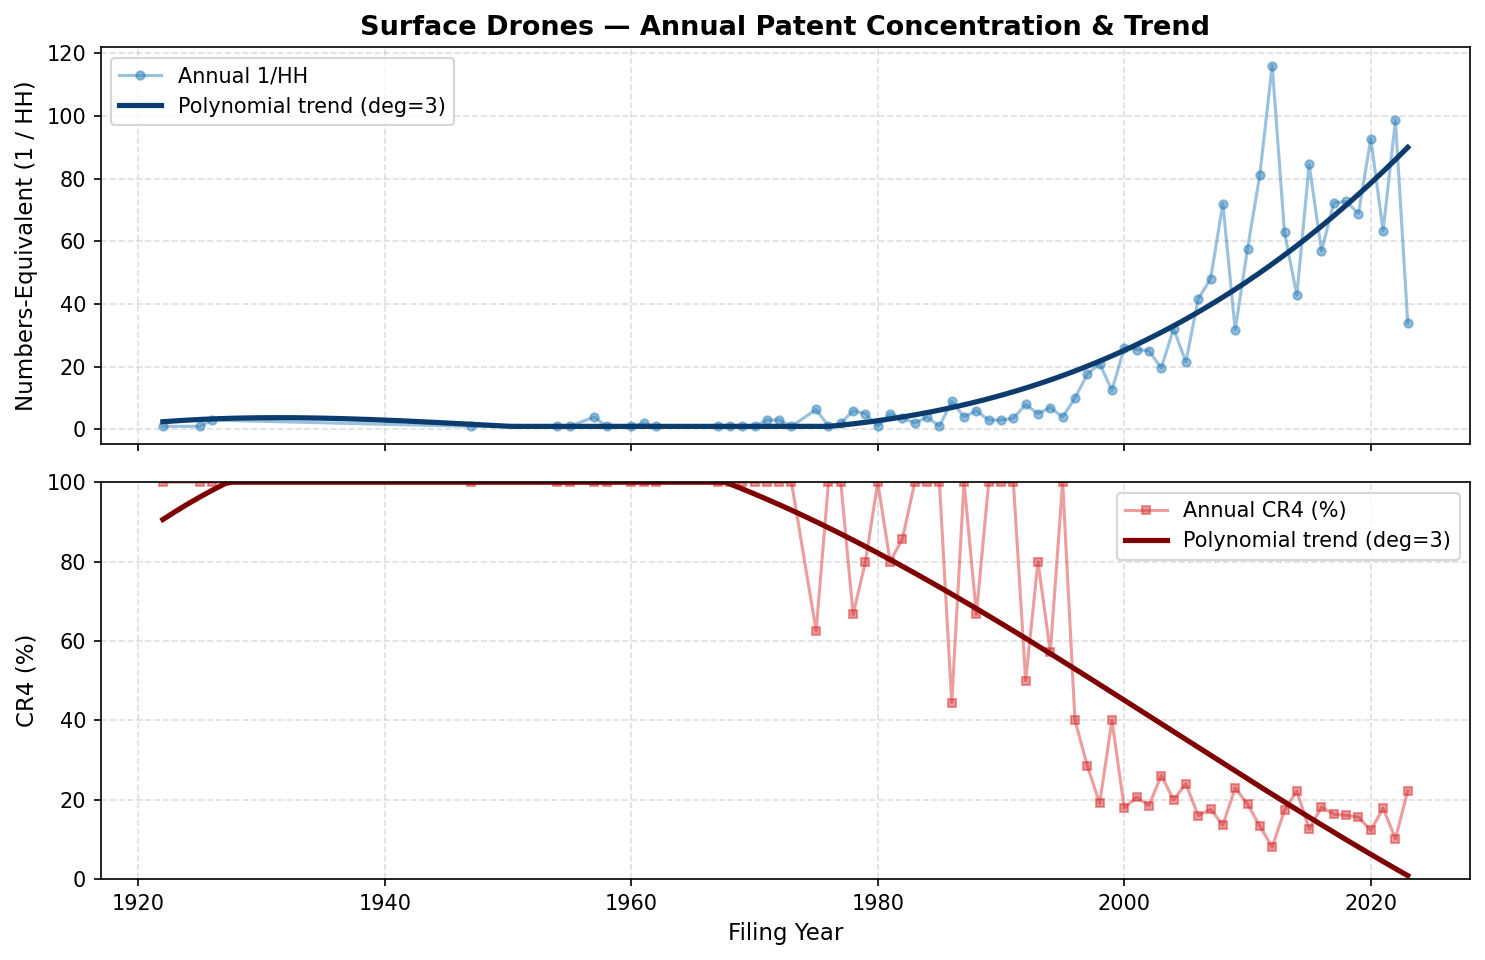

In [47]:
import numpy as np
import matplotlib.pyplot as plt

TRUNCATED_YEARS = [2024, 2025, 2026]
POLY_DEGREE = 3  # Use 2 for a simpler curve, 3 to capture inflection points

plot_df = conc_by_year.sort_values('year').copy()
fit_df = plot_df[~plot_df['year'].isin(TRUNCATED_YEARS)]

x = fit_df['year'].to_numpy()
x_grid = np.linspace(x.min(), x.max(), 200)

poly_inv_hh = np.poly1d(np.polyfit(x, fit_df['1/HH'], deg=POLY_DEGREE))
poly_cr4 = np.poly1d(np.polyfit(x, fit_df['CR4 (%)'], deg=POLY_DEGREE))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, dpi=150)

# Panel 1: Numbers-Equivalent (1/HH)
ax1.plot(
    plot_df['year'], plot_df['1/HH'],
    color='#1f77b4', marker='o', alpha=0.45, linewidth=1.5, markersize=4,
    label='Annual 1/HH'
)
ax1.plot(
    x_grid, np.maximum(1, poly_inv_hh(x_grid)),
    color='#0b3c6d', linewidth=2.5,
    label=f'Polynomial trend (deg={POLY_DEGREE})'
)
ax1.set_ylabel('Numbers-Equivalent (1 / HH)', fontsize=11)
ax1.set_title('Surface Drones — Annual Patent Concentration & Trend', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper left', frameon=True)

# Panel 2: Top-4 Concentration Ratio (CR4 %)
ax2.plot(
    plot_df['year'], plot_df['CR4 (%)'],
    color='#d62728', marker='s', alpha=0.45, linewidth=1.5, markersize=4,
    label='Annual CR4 (%)'
)
ax2.plot(
    x_grid, np.clip(poly_cr4(x_grid), 0, 100),
    color='#7f0000', linewidth=2.5,
    label=f'Polynomial trend (deg={POLY_DEGREE})'
)
ax2.set_ylabel('CR4 (%)', fontsize=11)
ax2.set_xlabel('Filing Year', fontsize=11)
ax2.set_ylim(0, min(100, plot_df['CR4 (%)'].max() * 1.15))
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='upper right', frameon=True)

# Shade truncated filing years if present
trunc_in_data = [y for y in TRUNCATED_YEARS if y in plot_df['year'].values]
if trunc_in_data:
    for ax in (ax1, ax2):
        ax.axvspan(
            min(trunc_in_data) - 0.5, max(trunc_in_data) + 0.5,
            color='gray', alpha=0.15, label='Truncated filing window'
        )
    ax1.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

# Answering Step 2 questions:

In [48]:
# 1. sector families (CPC codes OR keywords), with their year = earliest priority year
by_cpc = (
    db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, SECTOR_CPC_PREFIXES))
)
sector_ids = by_cpc

if SECTOR_KEYWORDS:
    by_kw = (
        db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition(SECTOR_KEYWORDS))
    )
    sector_ids = by_cpc.union(by_kw)

family_year = func.min(TLS201_APPLN.earliest_filing_year)
families = (
    db.query(TLS201_APPLN.docdb_family_id.label("unit_id"), family_year.label("year"))
    .filter(TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(sector_ids.subquery().select()))
    .group_by(TLS201_APPLN.docdb_family_id)
    .having(family_year.between(YEAR_MIN, YEAR_MAX))
    .subquery()
)

# 2. the applicants of every family (one row per family and person)
q_sector = (
    db.query(families.c.unit_id, families.c.year, TLS206_PERSON.psn_id, TLS206_PERSON.psn_name,
             TLS206_PERSON.psn_sector, func.trim(TLS206_PERSON.person_ctry_code).label("person_ctry_code"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
    .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)
    .distinct()
)
raw_sector = patstat.df(q_sector)

# 3. the CPC codes of every family (for the subfields)
q_cpc = (
    db.query(families.c.unit_id, families.c.year,
             func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("cpc"))
    .select_from(families)
    .join(TLS201_APPLN, TLS201_APPLN.docdb_family_id == families.c.unit_id)
    .join(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id == TLS201_APPLN.appln_id)
    .distinct()
)
family_cpc = patstat.df(q_cpc)
print(f"{raw_sector['unit_id'].nunique():,} families")

1,918 families


In [49]:
# 4. the first patent ever (in any field) of each applicant, to identify newcomers to patenting
psn_ids = [int(i) for i in raw_sector["psn_id"].unique()]
first_patents = []
for start in range(0, len(psn_ids), 5000):                      # in chunks, to keep each query small
    q_first = (
        db.query(TLS206_PERSON.psn_id, func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year"))
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
        .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
        .filter(TLS206_PERSON.psn_id.in_(psn_ids[start:start + 5000]),
                TLS207_PERS_APPLN.applt_seq_nr > 0,
                TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX))   # drops the 9999 placeholders
        .group_by(TLS206_PERSON.psn_id)
    )
    first_patents.append(patstat.df(q_first))
first_patents = pd.concat(first_patents)

In [50]:
first_patents # for each patent, the earliest filing (we are reasoning on family level here)

,psn_id,first_patent_year
0,13372884,2021
1,28055310,1996
2,32612631,1997
3,4260928,1987
4,27290267,1911
...,...,...
2137,33584951,2012
2138,30264055,2012
2139,3424280,2008
2140,23261380,2014


In [51]:
def prepare_applicants(raw):
    "From (unit_id, year, person) rows to one row per (unit_id, applicant) with type and country."
    df = raw.copy()

    # 1. the consolidated name of each applicant
    df["applicant"] = df["psn_name"].map(consolidated_names(df["psn_name"]))

    # 2. the type of applicant
    df["type"] = df["psn_sector"].map(applicant_type)

    # 3. one country per applicant: the most frequent known one
    df["ctry"] = df["person_ctry_code"].replace("", np.nan)
    known = df.dropna(subset=["ctry"]).drop_duplicates(["unit_id", "applicant", "ctry"])
    main_country = known.groupby("applicant")["ctry"].agg(lambda c: c.value_counts().index[0])
    df["ctry"] = df["applicant"].map(main_country)

    # 4. one row per (patent, applicant)
    return df[["unit_id", "year", "applicant", "type", "ctry"]].drop_duplicates(["unit_id", "applicant"])

In [52]:
raw_sector

,unit_id,year,psn_id,psn_name,psn_sector,person_ctry_code
0,7652787,2000,8050349,ENERCON (ALOYS WOBBEN),COMPANY,DE
1,7652787,2000,8050349,ENERCON (ALOYS WOBBEN),COMPANY,
2,26877844,2000,351185,AEROVIRONMENT,COMPANY,US
3,24457072,2000,11636336,HALLIBURTON ENERGY SERVICES GROUP,COMPANY,US
4,25003089,2000,7992020,EMC TEST SYSTEMS,COMPANY,US
...,...,...,...,...,...,...
3128,86824325,2023,2309816,BEIJING APAKELAN TECHNOLOGY COMPANY,COMPANY,
3129,87020213,2023,191103226,"HAIYUNLIAN TECHNOLOGY (SUZHOU) CO., LTD.",UNKNOWN,
3130,88233944,2023,188758575,SHANDONG MARINE SCIENCE RESEARCH INSTITUTE (QI...,UNKNOWN,
3131,88255087,2023,15095128,JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,UNIVERSITY,


In [53]:
links = prepare_applicants(raw_sector)

# first patent ever of each consolidated applicant: the earliest among the PATSTAT names it groups
psn = raw_sector[["psn_id", "psn_name"]].drop_duplicates().merge(first_patents, on="psn_id")
psn["applicant"] = psn["psn_name"].map(consolidated_names(psn["psn_name"]))
first_ever = psn.groupby("applicant")["first_patent_year"].min()

print(f"{links['applicant'].nunique():,} applicants on {links['unit_id'].nunique():,} families")

2,045 applicants on 1,918 families


##  Question 1: how concentrated is the field, and is it consolidating?

In [54]:
complete = links[links["year"] <= LAST_COMPLETE_YEAR].copy()
families_per_applicant = complete.groupby("applicant")["unit_id"].nunique()

pd.Series(six_measures(families_per_applicant.to_numpy()), name=SECTOR_NAME).round(3).to_frame()

,Surface Drones
firms,2033.000
patents (sum over firms),2848.000
CV,1.591
CR4 (%),5.162
CR8 (%),7.725
HH,0.002
1/HH,575.991
Lotka L,-1.874
Lotka p-value,0.000
Gini,0.266


In [55]:
complete

,unit_id,year,applicant,type,ctry
0,7652787,2000,ENERCON ALOYS WOBBEN,firm,DE
2,26877844,2000,AEROVIRONMENT,firm,US
3,24457072,2000,HALLIBURTON ENERGY SERVICES,firm,US
4,25003089,2000,EMC TEST SYSTEMS,firm,US
5,19770768,2000,HEEREMA MARINE CONTRACTORS NEDERLAND,firm,NL
...,...,...,...,...,...
3109,88918589,2022,RADMANESH MEYSAM,unknown,IR
3110,86329517,2022,ASSOCIA O BLC3 CAMPUS DE TECNOLOGIA E INOVA O,unknown,PT
3111,86329517,2022,ASSOCIA O CECOLAB COLLABORATIVE LABORATORY TOW...,unknown,PT
3112,88022731,2022,KOTKAR ENERGY DYNAMICS,unknown,IN


Still, we have to deal with **multiple applicant names pointing to the same underlying firm**. 

Let's look at the **samsung example**.

In [56]:
# Or case-insensitive substring match for any Samsung entity (e.g., "SAMSUNG ELECTRONICS", "SAMSUNG HEAVY INDUSTRIES")
rows = complete[complete["applicant"].str.contains("SAMSUNG", case=False, na=False)]

In [57]:
rows

,unit_id,year,applicant,type,ctry
39,19708426,2001,SAMSUNG GWANGJU ELECTRONICS,firm,KR
429,42083656,2008,SAMSUNG HEAVY INDUSTRIES,firm,KR
598,43929513,2009,SAMSUNG HEAVY INDUSTRIES,firm,KR
746,45505232,2010,SAMSUNG HEAVY INDUSTRIES,firm,KR
748,46136527,2010,SAMSUNG HEAVY INDUSTRIES,firm,KR
...,...,...,...,...,...
2914,85110967,2021,SAMSUNG HEAVY INDUSTRIES,firm,KR
2915,85225505,2021,SAMSUNG HEAVY INDUSTRIES,firm,KR
2916,85225578,2021,SAMSUNG HEAVY INDUSTRIES,firm,KR
2917,85225489,2021,SAMSUNG C T,firm,KR


In [58]:
names_embeddings = model.encode(
    complete['applicant'].astype(str).tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

# Compute similarity matrix

sim_matrix = names_embeddings @ names_embeddings.T

# Convert similarity to distance (clip to avoid floating-point negatives like -1e-7)
dist_matrix = np.clip(1 - sim_matrix, 0, None)

from sklearn.cluster import AgglomerativeClustering

# Cluster using a distance threshold (e.g., similarity >= 0.85 -> distance <= 0.15)
clustering = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0.35,
    metric="precomputed",
    linkage="average",  # 'average' or 'complete' prevents chaining; avoid 'single'
)

complete['cluster'] = clustering.fit_predict(dist_matrix)

# number of clusters 

len(np.unique(complete['cluster']))

# 1. Create a dictionary mapping each name in X to its predicted cluster ID
cluster_map = dict(zip(complete["applicant"].astype(str), complete["cluster"]))


def my_harmonisation(name):
    return cluster_map.get(name,name)

complete['cluster'] = complete["applicant"].map(my_harmonisation)

Batches:   0%|          | 0/89 [00:00<?, ?it/s]

In [59]:
complete

,unit_id,year,applicant,type,ctry,cluster
0,7652787,2000,ENERCON ALOYS WOBBEN,firm,DE,18
2,26877844,2000,AEROVIRONMENT,firm,US,189
3,24457072,2000,HALLIBURTON ENERGY SERVICES,firm,US,14
4,25003089,2000,EMC TEST SYSTEMS,firm,US,1375
5,19770768,2000,HEEREMA MARINE CONTRACTORS NEDERLAND,firm,NL,159
...,...,...,...,...,...,...
3109,88918589,2022,RADMANESH MEYSAM,unknown,IR,607
3110,86329517,2022,ASSOCIA O BLC3 CAMPUS DE TECNOLOGIA E INOVA O,unknown,PT,278
3111,86329517,2022,ASSOCIA O CECOLAB COLLABORATIVE LABORATORY TOW...,unknown,PT,278
3112,88022731,2022,KOTKAR ENERGY DYNAMICS,unknown,IN,552


In [60]:
complete['cluster_label'] = (
    complete.groupby('cluster')['applicant']
    .transform(lambda s: min(s.dropna().astype(str), key=lambda x: (len(x), x), default=None))
)

In [61]:
complete

,unit_id,year,applicant,type,ctry,cluster,cluster_label
0,7652787,2000,ENERCON ALOYS WOBBEN,firm,DE,18,ENI
2,26877844,2000,AEROVIRONMENT,firm,US,189,AEROVIRONMENT
3,24457072,2000,HALLIBURTON ENERGY SERVICES,firm,US,14,HALL MARK
4,25003089,2000,EMC TEST SYSTEMS,firm,US,1375,EMC TEST SYSTEMS
5,19770768,2000,HEEREMA MARINE CONTRACTORS NEDERLAND,firm,NL,159,HEEREMA MARINE CONTRACTORS
...,...,...,...,...,...,...,...
3109,88918589,2022,RADMANESH MEYSAM,unknown,IR,607,RADMANESH MEYSAM
3110,86329517,2022,ASSOCIA O BLC3 CAMPUS DE TECNOLOGIA E INOVA O,unknown,PT,278,ASSOCIA O BLC3 CAMPUS DE TECNOLOGIA E INOVA O
3111,86329517,2022,ASSOCIA O CECOLAB COLLABORATIVE LABORATORY TOW...,unknown,PT,278,ASSOCIA O BLC3 CAMPUS DE TECNOLOGIA E INOVA O
3112,88022731,2022,KOTKAR ENERGY DYNAMICS,unknown,IN,552,KOTKAR ENERGY DYNAMICS


In [62]:
complete['ctry'] = complete['ctry'].fillna('OTHER')

In [63]:
def get_top_country(s):
    # Filter out missing values and 'OTHER' (case-insensitive check just in case)
    valid = s.dropna()[s.dropna().str.upper() != 'OTHER']
    
    if valid.empty:
        return 'OTHER'
    
    # value_counts() sorts from most frequent to least frequent
    return valid.value_counts().index[0]

complete['cluster_country'] = (
    complete.groupby('cluster_label')['ctry']
    .transform(get_top_country)
)

In [64]:
complete

,unit_id,year,applicant,type,ctry,cluster,cluster_label,cluster_country
0,7652787,2000,ENERCON ALOYS WOBBEN,firm,DE,18,ENI,DE
2,26877844,2000,AEROVIRONMENT,firm,US,189,AEROVIRONMENT,US
3,24457072,2000,HALLIBURTON ENERGY SERVICES,firm,US,14,HALL MARK,US
4,25003089,2000,EMC TEST SYSTEMS,firm,US,1375,EMC TEST SYSTEMS,US
5,19770768,2000,HEEREMA MARINE CONTRACTORS NEDERLAND,firm,NL,159,HEEREMA MARINE CONTRACTORS,NL
...,...,...,...,...,...,...,...,...
3109,88918589,2022,RADMANESH MEYSAM,unknown,IR,607,RADMANESH MEYSAM,IR
3110,86329517,2022,ASSOCIA O BLC3 CAMPUS DE TECNOLOGIA E INOVA O,unknown,PT,278,ASSOCIA O BLC3 CAMPUS DE TECNOLOGIA E INOVA O,PT
3111,86329517,2022,ASSOCIA O CECOLAB COLLABORATIVE LABORATORY TOW...,unknown,PT,278,ASSOCIA O BLC3 CAMPUS DE TECNOLOGIA E INOVA O,PT
3112,88022731,2022,KOTKAR ENERGY DYNAMICS,unknown,IN,552,KOTKAR ENERGY DYNAMICS,IN


In [65]:
unit_per_firm_year = (
    complete
    .groupby(['year', 'cluster_label', 'cluster_country'], as_index=False)['unit_id']
    .nunique()
    .rename(columns={
        'cluster_label': 'firm',
        'cluster_country': 'country',
        'unit_id': 'units_per_firm'
    })
    .sort_values(by=['year', 'units_per_firm'], ascending=[True, False])
    .reset_index(drop=True)
)

In [66]:
unit_per_firm_year

,year,firm,country,units_per_firm
0,2000,AEROVIRONMENT,US,2
1,2000,CALVERLEY GRANT HOWARD,US,1
2,2000,DEN HARTOGH FRANS ARIEN,NL,1
3,2000,EMC TEST SYSTEMS,US,1
4,2000,ENI,DE,1
...,...,...,...,...
2169,2022,XING ZHOU TIAN,US,1
2170,2022,Z KNOWLEDGE,CN,1
2171,2022,ZHEJIANG HUADONG SURVEYING AND MAPPING AND ENG...,OTHER,1
2172,2022,ZHONG CHUNZHENG,OTHER,1


In [67]:
unit_conc_by_year = (
    unit_per_firm_year
    .groupby('year')['units_per_firm']
    .agg([
        ('firms', 'count'),
        ('patents', 'sum'),
        ('HH', herfindahl),
        ('1/HH', lambda x: 1 / herfindahl(x)),
        ('CR4 (%)', lambda x: concentration_ratio(x, 4)),
    ])
    .reset_index()
)

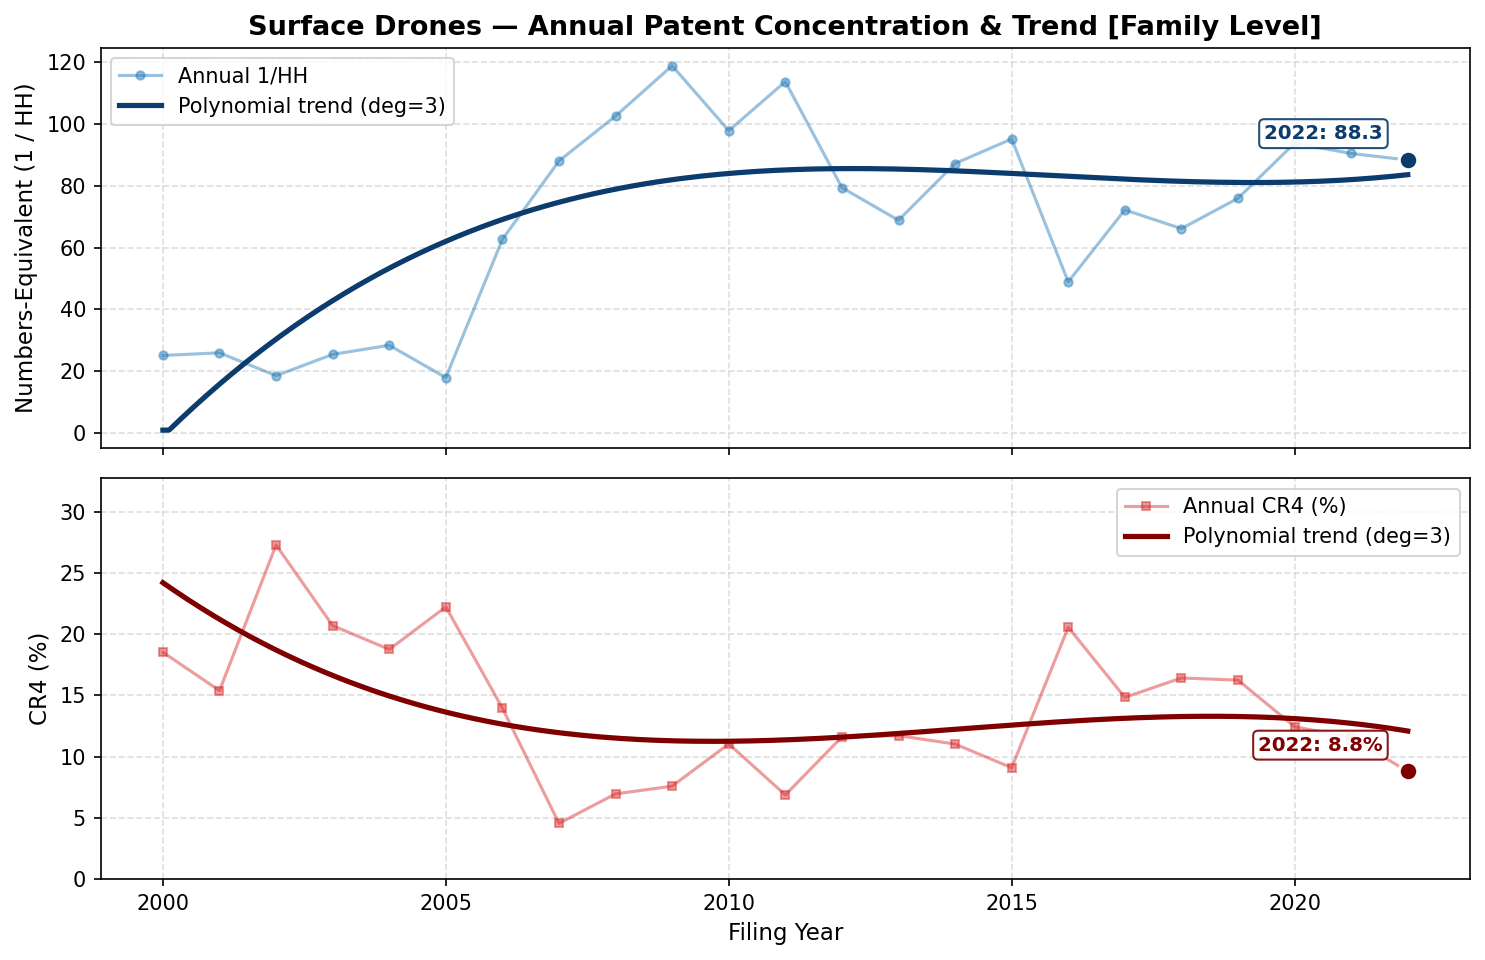

In [68]:
import numpy as np
import matplotlib.pyplot as plt

TRUNCATED_YEARS = [2024, 2025, 2026]
POLY_DEGREE = 3  # Use 2 for a simpler curve, 3 to capture inflection points

plot_df = unit_conc_by_year.sort_values('year').copy()
fit_df = plot_df[~plot_df['year'].isin(TRUNCATED_YEARS)]

x = fit_df['year'].to_numpy()
x_grid = np.linspace(x.min(), x.max(), 200)

poly_inv_hh = np.poly1d(np.polyfit(x, fit_df['1/HH'], deg=POLY_DEGREE))
poly_cr4 = np.poly1d(np.polyfit(x, fit_df['CR4 (%)'], deg=POLY_DEGREE))

# Choose which "last value" to highlight:
# Use `plot_df.iloc[-1]` for the very last point in the dataset,
# or `fit_df.iloc[-1]` for the last complete (non-truncated) year.
last_row = plot_df.iloc[-1]
last_year = int(last_row['year'])
last_inv_hh = last_row['1/HH']
last_cr4 = last_row['CR4 (%)']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, dpi=150)

# Panel 1: Numbers-Equivalent (1/HH)
ax1.plot(
    plot_df['year'], plot_df['1/HH'],
    color='#1f77b4', marker='o', alpha=0.45, linewidth=1.5, markersize=4,
    label='Annual 1/HH'
)
ax1.plot(
    x_grid, np.maximum(1, poly_inv_hh(x_grid)),
    color='#0b3c6d', linewidth=2.5,
    label=f'Polynomial trend (deg={POLY_DEGREE})'
)
ax1.scatter(
    [last_year], [last_inv_hh],
    color='#0b3c6d', edgecolor='white', linewidth=1.5, s=80, zorder=5
)
ax1.annotate(
    f'{last_year}: {last_inv_hh:.1f}',
    xy=(last_year, last_inv_hh),
    xytext=(-12, 10), textcoords='offset points',
    ha='right', fontsize=9.5, fontweight='bold', color='#0b3c6d',
    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='#0b3c6d', alpha=0.9)
)
ax1.set_ylabel('Numbers-Equivalent (1 / HH)', fontsize=11)
ax1.set_title('Surface Drones — Annual Patent Concentration & Trend [Family Level]', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='upper left', frameon=True)

# Panel 2: Top-4 Concentration Ratio (CR4 %)
ax2.plot(
    plot_df['year'], plot_df['CR4 (%)'],
    color='#d62728', marker='s', alpha=0.45, linewidth=1.5, markersize=4,
    label='Annual CR4 (%)'
)
ax2.plot(
    x_grid, np.clip(poly_cr4(x_grid), 0, 100),
    color='#7f0000', linewidth=2.5,
    label=f'Polynomial trend (deg={POLY_DEGREE})'
)
ax2.scatter(
    [last_year], [last_cr4],
    color='#7f0000', edgecolor='white', linewidth=1.5, s=80, zorder=5
)
ax2.annotate(
    f'{last_year}: {last_cr4:.1f}%',
    xy=(last_year, last_cr4),
    xytext=(-12, 10), textcoords='offset points',
    ha='right', fontsize=9.5, fontweight='bold', color='#7f0000',
    bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='#7f0000', alpha=0.9)
)
ax2.set_ylabel('CR4 (%)', fontsize=11)
ax2.set_xlabel('Filing Year', fontsize=11)
ax2.set_ylim(0, min(100, plot_df['CR4 (%)'].max() * 1.2))
ax2.grid(True, linestyle='--', alpha=0.4)
ax2.legend(loc='upper right', frameon=True)

# Shade truncated filing years if present
trunc_in_data = [y for y in TRUNCATED_YEARS if y in plot_df['year'].values]
if trunc_in_data:
    for ax in (ax1, ax2):
        ax.axvspan(
            min(trunc_in_data) - 0.5, max(trunc_in_data) + 0.5,
            color='gray', alpha=0.15, label='Truncated filing window'
        )
    ax1.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

## Question 2: who are the incumbents, and who are the new entrants?

**Top applicants.** 

The largest applicants with their type and country, their families, the year of their first family in the sector, and their status:

- **incumbent**: first family in the sector before SPLIT_YEAR;
- **entrant**: first family in the sector from SPLIT_YEAR on.

In [69]:
by_applicant = links.groupby("applicant")
top_applicants = pd.DataFrame({
    "type": by_applicant["type"].first(),
    "country": by_applicant["ctry"].first(),
    "families": by_applicant["unit_id"].nunique(),
    f"families since {SPLIT_YEAR}": links[links["year"] >= SPLIT_YEAR].groupby("applicant")["unit_id"].nunique(),
    "first year in the sector": by_applicant["year"].min(),
    "last year in the sector": by_applicant["year"].max(),
    "first patent ever": first_ever,
}).dropna(subset=["families"]).fillna({f"families since {SPLIT_YEAR}": 0})
top_applicants["status"] = np.where(top_applicants["first year in the sector"] < SPLIT_YEAR, "incumbent", "entrant")
top_applicants = top_applicants.sort_values("families", ascending=False)
top_applicants.head(TOP_N)

,type,country,families,families since 2015,first year in the sector,last year in the sector,first patent ever,status
applicant,,,,,,,,
SAMSUNG HEAVY INDUSTRIES,firm,KR,71,60.0,2008,2021,1993,incumbent
ITREC,firm,NL,26,19.0,2002,2022,1997,incumbent
GE GENERAL ELECTRIC,firm,US,26,15.0,2006,2019,1905,incumbent
BOEING,firm,US,24,9.0,2006,2020,1944,incumbent
WALMART APOLLO,firm,US,22,22.0,2015,2017,2012,entrant
ZHEJIANG OCEAN UNIVERSITY,university,CN,18,17.0,2014,2021,2009,incumbent
HARBIN ENGINEERING UNIVERSITY,university,None,17,17.0,2016,2022,2002,entrant
BRAIN,firm,US,16,7.0,2013,2017,2010,incumbent
JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY,university,CN,16,16.0,2015,2023,2005,entrant


## Entry and exit, year by year. 

For each year $t$ :

- active applicants: applicants with at least one family in $t$;
- new to the sector: active applicants whose first family in the sector is in $t$;
- new to patenting: active applicants whose first patent ever, in any field, is in $t$ ("they never patented before");
- entrants' share of families: share of the families of $t$ with at least one applicant new to the sector;
rate of disappearance: share of the applicants active in 
 that never file again in the sector. It is shown only up to 3 years before the last complete year: an applicant silent in the last years may simply not be published yet.

 
In the first years of the window almost every applicant looks "new", because we do not see its families before `YEAR_MIN`: read entry from a few years after `YEAR_MIN`.

In [70]:
first_year = by_applicant["year"].min()      # first family of each applicant in the sector
last_year = by_applicant["year"].max()       # last family of each applicant in the sector

active = links[["applicant", "year"]].drop_duplicates()
active["new to the sector"] = active["year"] == active["applicant"].map(first_year)
active["new to patenting"] = active["year"] == active["applicant"].map(first_ever)
active["last family"] = active["year"] == active["applicant"].map(last_year)

entry_exit = active.groupby("year").agg(
    active_applicants=("applicant", "count"),
    new_to_the_sector=("new to the sector", "sum"),
    new_to_patenting=("new to patenting", "sum"),
    leaving=("last family", "sum"),
)
entry_exit["rate of disappearance (%)"] = entry_exit["leaving"] / entry_exit["active_applicants"] * 100
entry_exit.loc[entry_exit.index > LAST_COMPLETE_YEAR - 3, "rate of disappearance (%)"] = np.nan

# share of each year's families with at least one applicant new to the sector
links_new = links.assign(new=links["year"] == links["applicant"].map(first_year))
entry_exit["entrants' share of families (%)"] = links_new.groupby(["year", "unit_id"])["new"].any().groupby("year").mean() * 100
entry_exit.round(1)

,active_applicants,new_to_the_sector,new_to_patenting,leaving,rate of disappearance (%),entrants' share of families (%)
year,,,,,,
2000,28,28,16,21,75.0,100.0
2001,28,26,17,22,78.6,94.4
2002,22,22,12,12,54.5,100.0
2003,28,27,20,24,85.7,94.7
2004,31,30,21,25,80.6,93.3
2005,19,15,13,16,84.2,100.0
2006,77,72,64,64,83.1,96.4
2007,90,86,66,78,86.7,97.0
2008,110,98,74,91,82.7,97.9


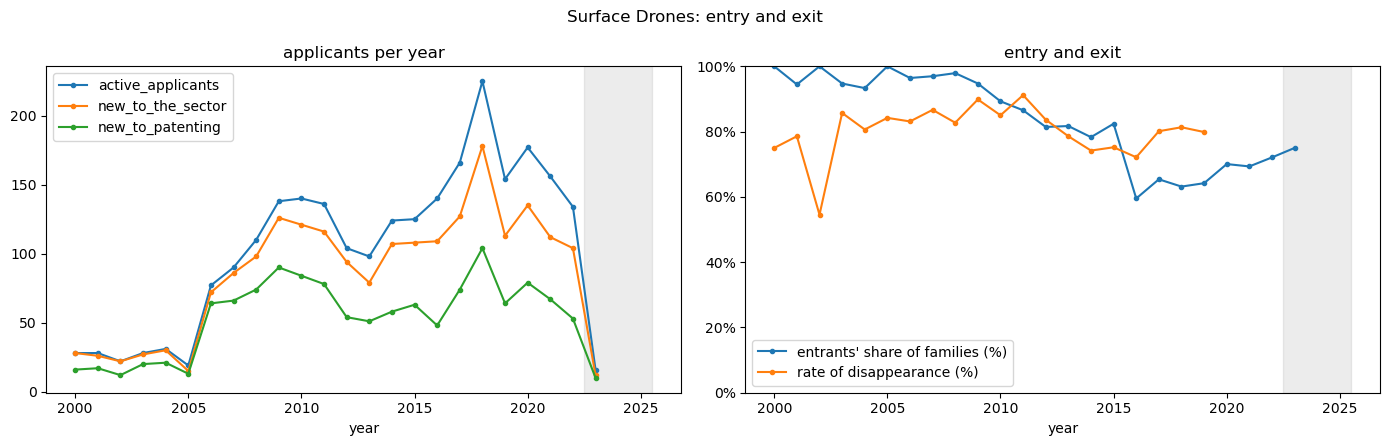

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
entry_exit[["active_applicants", "new_to_the_sector", "new_to_patenting"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="applicants per year", xlabel="year")
entry_exit[["entrants' share of families (%)", "rate of disappearance (%)"]].plot(ax=axes[1], marker="o", ms=3)
axes[1].set(title="entry and exit", xlabel="year", ylim=(0, 100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes:
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)   # incomplete years
fig.suptitle(f"{SECTOR_NAME}: entry and exit")
plt.tight_layout()
plt.show()

In [72]:
top = top_applicants.head(TOP_N)
incumbents = top[top["status"] == "incumbent"].index.tolist()
entrants = top[top["status"] == "entrant"].index.tolist()
recent_entry = entry_exit.loc[LAST_COMPLETE_YEAR - 4:LAST_COMPLETE_YEAR, "entrants' share of families (%)"].mean()

print(
    f"Who are the incumbents, and who are the new entrants?\n\n"
    f"Among the {TOP_N} largest applicants, {len(incumbents)} are incumbents and {len(entrants)} are entrants.\n"
    f"Largest incumbents: {', '.join(incumbents[:3]) or 'none'}.\n"
    f"Largest entrants (first family from {SPLIT_YEAR}): {', '.join(entrants[:3]) or 'none'}.\n"
    f"In the last five complete years, on average {recent_entry:.0f}% of each year's families had at least one applicant new to the sector."
)

Who are the incumbents, and who are the new entrants?

Among the 15 largest applicants, 12 are incumbents and 3 are entrants.
Largest incumbents: SAMSUNG HEAVY INDUSTRIES, ITREC, GE GENERAL ELECTRIC.
Largest entrants (first family from 2015): WALMART APOLLO, HARBIN ENGINEERING UNIVERSITY, JIANGSU UNIVERSITY OF SCIENCE AND TECHNOLOGY.
In the last five complete years, on average 68% of each year's families had at least one applicant new to the sector.


## Question 3: which subfields are growing fastest?

A **subfield** is a CPC group inside the sector.

<u>Note</u>:

Unlike aerial drones (which have a dedicated B64U subclass), Unmanned Surface Vehicles (USVs) / **surface drones do not have a single standalone CPC subclass**. Instead, patents in this sector cluster across dedicated B63B structural subgroups, autonomous navigation/control groups in G05D and G08G, and specialized deployment/mission subgroups.

In [73]:
RECENT = (LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)          # the last 5 complete years
PAST = (RECENT[0] - 5, RECENT[0] - 1)                          # the 5 years before


def subfield(cpc):
    "CPC group with the first two digits after the slash: H01M8/1004 -> H01M8/10."
    main_group, subgroup = cpc.split("/")
    return f"{main_group}/{subgroup[:2]}"


in_sector = family_cpc[family_cpc["cpc"].str.startswith(tuple(SECTOR_CPC_PREFIXES))].copy()
in_sector["subfield"] = in_sector["cpc"].map(subfield)
in_sector = in_sector.drop_duplicates(["unit_id", "subfield"])

past = in_sector[in_sector["year"].between(*PAST)].groupby("subfield")["unit_id"].nunique()
recent = in_sector[in_sector["year"].between(*RECENT)].groupby("subfield")["unit_id"].nunique()
subfields = pd.DataFrame({f"families {PAST[0]}-{PAST[1]}": past, f"families {RECENT[0]}-{RECENT[1]}": recent}).fillna(0)
subfields["growth (%)"] = (subfields.iloc[:, 1] / subfields.iloc[:, 0] - 1) * 100
subfields = subfields.sort_values(subfields.columns[1], ascending=False)
subfields.round(1)

,families 2013-2017,families 2018-2022,growth (%)
subfield,,,
B63B35/00,160,390.0,143.8
G05D1/00,221,92.0,-58.4
B63B2035/00,25,86.0,244.0
B63G8/00,41,32.0,-22.0
G05D1/02,18,27.0,50.0
G08G3/00,3,4.0,33.3
B63G13/00,2,2.0,0.0
B64U70/93,8,1.0,-87.5
B64U60/10,4,0.0,-100.0


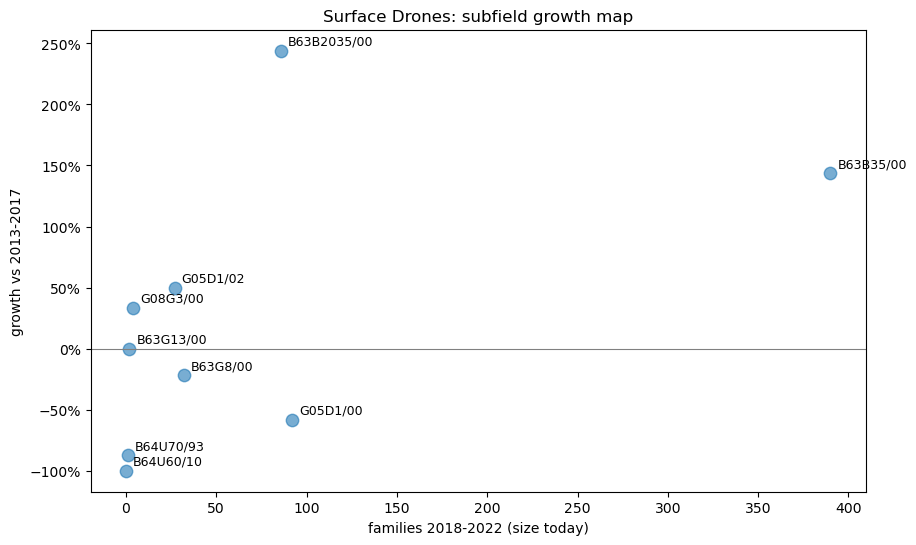

In [74]:
plot = subfields[subfields.iloc[:, 0] > 0]                   # growth is defined only if the subfield existed before
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(plot.iloc[:, 1], plot["growth (%)"], s=80, alpha=0.6)
for name, row in plot.iterrows():
    ax.annotate(name, (row.iloc[1], row["growth (%)"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="grey", lw=0.8)
ax.set(title=f"{SECTOR_NAME}: subfield growth map", xlabel=f"families {RECENT[0]}-{RECENT[1]} (size today)",
       ylabel=f"growth vs {PAST[0]}-{PAST[1]}")
ax.yaxis.set_major_formatter(PercentFormatter(100))
plt.show()

In [76]:
# fastest-growing subfields, among those at least as large as the median subfield today
size_today = plot.iloc[:, 1]
fastest = plot[size_today >= size_today.median()].sort_values("growth (%)", ascending=False).head(3)

results = ", ".join(f"{name} ({row['growth (%)']:+.0f}%)" for name, row in fastest.iterrows())

print("Which subfields are growing fastest?")
print(results)
print(
    f"Growth of families from {PAST[0]}-{PAST[1]} to {RECENT[0]}-{RECENT[1]}, "
    "among the subfields at least as large as the median one. "
)

Which subfields are growing fastest?
B63B2035/00 (+244%), B63B35/00 (+144%), G05D1/02 (+50%)
Growth of families from 2013-2017 to 2018-2022, among the subfields at least as large as the median one. 


### 1. B63B 35/00 — The Core Structure (Invention Information)
**What it means**: "Vessels or like floating structures adapted for special purposes."

**When an examiner uses it**: When the patent's primary physical invention is a specialized hull or floating structure that doesn't fit into standard ship categories (like tankers, bulk carriers, or ferries).

<u>Example</u>: A patent claiming a uniquely shaped trimaran hull built specifically to stabilize a hydrographic survey drone. Because the hull itself is the special-purpose invention, it gets 

### 2. B63B 2035/00 — The "2000-Series" Indexing Tag (Additional Information)


**What it means**: An orthogonal/indexing code that mirrors B63B 35/00 to capture secondary details, specific applications, or sub-features that the main IPC/CPC tree doesn't break down finely enough.

**Why the 2000 prefix exists**: CPC is built on top of the global IPC (International Patent Classification) system. To keep international compatibility, the EPO and USPTO aren't allowed to change the official IPC numbering (B63B 35/00). Instead, whenever they want to add extra, fine-grained search tags, they add 2000 to the group number (35/00 $\rightarrow$ 2035/00).

When an examiner uses it: Usually as a secondary tag alongside another primary code. For instance, if a patent is primarily about a crane (B66C) or a control system (G05D), the examiner might slap a B63B 2035/00 (or a child code like B63B 2035/006 for marine drone handling) onto it just to index the fact that "this takes place on a special-purpose vessel."


### 3. G05D1/02 - Control of position or course in two dimensions

Widely covers autonomous navigation, path planning, obstacle avoidance, and guidance for mobile robots, AGVs, autonomous surface vessels, and self-driving vehicles. (<u>Note</u>: In the CPC scheme, G05D 1/02 was frozen on January 1, 2024, with newer autonomous vehicle/navigation filings reclassified into updated groups such as B60W 60/00 or newer G05D 1/20–1/80 subgroups.)

## Question 4: which forces shape the field? PEST analysis